In [176]:
import icarusplot
import uproot
import pandas as pd
import numpy as np
import ROOT
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import os
from GUNDAMOutputInfo import GUNDAMOutputInfo
from matplotlib.lines import Line2D

In [177]:
WD = '/Users/jskim/Documents/Neutrino/ICARUS/GUNDAM-1.9.X/work'

In [178]:
JobName = '250627_BadRegionRejection'

In [179]:
XsecOutputBaseDir = f'{WD}/output/{JobName}/Xsec'

In [180]:
def GetOutputDir(FolderName):
    return f'{WD}/run_configs/{FolderName}/output/{JobName}'

In [181]:
# VariableName = 'MuonCos'
# VariableName = 'MuonProtonCos'

# VariableName = 'deltaPT'
VariableName = 'deltaalphaT'

PhaseSpaceCut = 'AllSignal' if ('Cos' in VariableName) else 'MuonPLT0p8'
RecoSelStringForPhaseSpaceCut = '_MuonPLT0p8' if PhaseSpaceCut=='MuonPLT0p8' else ''

XsecVariableName = f'True{VariableName}'
VariableYMax = 0

if XsecVariableName=='TruedeltaPT':
    PlotVariableName = 'TruedeltaPT'
    VariableXTitle = r'$\delta p_{T}$ (GeV)'
    VariableYTitle = r'$\frac{d \sigma}{d \delta p_{T}}$ $\frac{cm^{2}}{(GeV/c) Ar}$'
    xMin=0.
    xMax=0.8
    VariableYMax = 1.3E-37
    if PhaseSpaceCut == 'MuonPLT0p8':
        VariableYMax = 0.5E-37
if XsecVariableName=='TruedeltaalphaT':
    PlotVariableName = 'TruedeltaalphaT'
    VariableXTitle = r'$\delta \alpha_{T}$ (degree)'
    VariableYTitle = r'$\frac{d \sigma}{d \delta \alpha_{T}}$ $\frac{cm^{2}}{(degree) Ar}$'
    xMin=0.
    xMax=180.
    VariableYMax = 4E-40
    if PhaseSpaceCut == 'MuonPLT0p8':
        VariableYMax = 1.5E-40
if XsecVariableName=='TrueMuonCos':
    PlotVariableName = 'TrueMuonCos'
    VariableXTitle = r'$\cos{\theta_{\mu}}$'
    VariableYTitle = r'$\frac{d \sigma}{d \cos{\theta_{\mu}}}$ $\frac{cm^{2}}{Ar}$'
    xMin=-1.
    xMax=1.
    VariableYMax = 2.5E-37
if XsecVariableName=='TrueMuonProtonCos':
    PlotVariableName = 'TrueMuonProtonCos'
    VariableXTitle = r'$\cos{\theta_{\mu,p}}$'
    VariableYTitle = r'$\frac{d \sigma}{d \cos{\theta_{\mu,p}}}$ $\frac{cm^{2}}{Ar}$'
    xMin=-1.
    xMax=1.
    VariableYMax = 4E-38

IsMuonCosPlot = ('MuonCos' in VariableName)

In [182]:
GUNDAMOutputInfos = [

    GUNDAMOutputInfo(
        Folder=GetOutputDir('250723_MultiplicativeTemplate'),
        FitConfig=f'SimFit{RecoSelStringForPhaseSpaceCut}_StatCovariance',
        DataEntry='RealData',
        SignalSel=PhaseSpaceCut,
        Latex='Data, simultaneous fit'
    ),

    GUNDAMOutputInfo(
        Folder=GetOutputDir('250723_MultiplicativeTemplate'),
        FitConfig=f'IndvFit{RecoSelStringForPhaseSpaceCut}_BarlowLLH',
        DataEntry='RealData',
        SignalSel=PhaseSpaceCut,
        Latex='Data, individual fit'
    ),



    # GUNDAMOutputInfo(
    #     Folder=GetOutputDir('250723_MultiplicativeTemplate'),
    #     FitConfig='IndvFit_MuonPLT0p8_BarlowLLH',
    #     DataEntry='RealData',
    #     SignalSel='MuonPLT0p8',
    #     Latex=r'Indv. fit'
    # ),

    # GUNDAMOutputInfo(
    #     Folder=GetOutputDir('250723_MultiplicativeTemplate'),
    #     FitConfig='SimFit_MuonPLT0p8_StatCovariance',
    #     DataEntry='RealData',
    #     SignalSel='MuonPLT0p8',
    #     Latex=r'Sim. fit'
    # ),


]

OutputColors = [
    'k',
    'orange',
]

# Theory values

In [183]:
# theory
TheoryXsecBaseDir = '/Users/jskim/docker/volumes/nusyst/work/250605_ReworkGeneratorPrediction/xsecs'

GeneratorInfos = [
    ['GENIE', '250611_GENIE_1MEvents', 'AR23_20i_00_000', 'Reference model'],
    # ['GENIE', '250725_GENIE_LQCDRWAdded_1MEvents', 'AR23_20i_00_000', r'GENIE (AR23_20i, LQCD z-exp $F_{A}$)'],
    # ['NuWro', '250616_NuWro_1MEvents', '21.09.2', 'NuWro (21.09.2)'],
    # ['GiBUU', '250617_GiBUU_Try0', 'r2025_02', 'GiBUU (r2025_02)'],
    # ['NEUT', '250625_NEUT_1M', '5.8.0', 'NEUT (5.8.0)'],
]
TheoryXsecValues = []
h_GENIE_xsec = 0
for i_G, GeneratorInfo in enumerate(GeneratorInfos):

    GeneratorName = GeneratorInfo[0]
    GeneratorJobName = GeneratorInfo[1]
    GeneratorConfig = GeneratorInfo[2]
    GeneratorLatex = GeneratorInfo[3]

    this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_AnaBin.csv'
    this_df = pd.read_csv(this_csv)
    BinCenters, BinErrors, h_diffxsec_sum = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()

    if GeneratorName=='GENIE' and i_G==0:
        h_GENIE_xsec = h_diffxsec_sum

    TheoryXsecValues.append( [BinCenters, BinErrors, h_diffxsec_sum] )

# X-sec comparison

Data, simultaneous fit
[0.43860379 0.33053908 0.3249272  0.30712899 0.35627899 0.30812519]
Data, individual fit
[0.38043541 0.28278158 0.26733129 0.25790414 0.30700679 0.26325332]


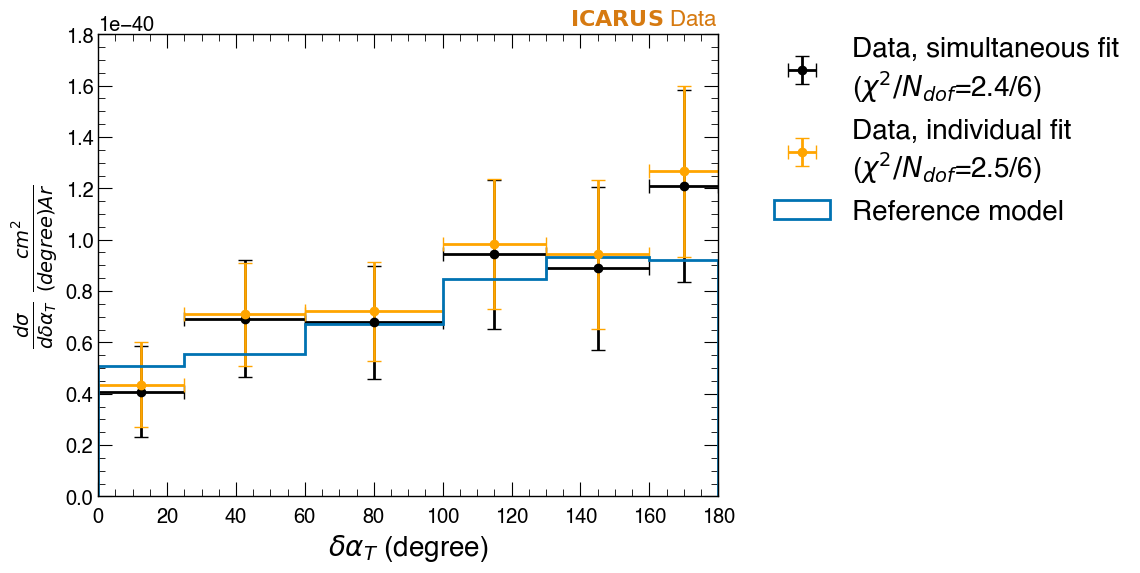

In [184]:
fig, ax = plt.subplots(figsize=(8,6))

y_max = -1
lgs_xsecs = []

IsMuonCosPlot = ('MuonCos' in VariableName)
if IsMuonCosPlot:

    y_boundary = 0.7320
    y_max_zoom = 0.12

    ax_zoom = fig.add_axes([0.21, 0.45, 0.36, 0.35])

for i_job, xsecinfo in enumerate(GUNDAMOutputInfos):

    XsecInfoLatex = xsecinfo.Latex
    SignalSel = xsecinfo.SignalSel
    ThisLabel = f'{XsecInfoLatex}'
    ThisColor = OutputColors[i_job]

    if 'SimFit' in xsecinfo.FitConfig:
        if VariableName in ['MuonCos', 'MuonProtonCos']:
            CalcXsecFilePath = xsecinfo.GetCalcXsecFile('MuonCos_and_MuonProtonCos')
        elif VariableName in ['deltaPT', 'deltaalphaT']:
            CalcXsecFilePath = xsecinfo.GetCalcXsecFile('deltaPT_and_deltaalphaT')
    else:
        CalcXsecFilePath = xsecinfo.GetCalcXsecFile(VariableName)

    with uproot.open(CalcXsecFilePath) as f:

        # To get the binning
        h_for_binning = f[f'calcXsec/plots/histograms/TrueSignal_{SignalSel}_{XsecVariableName}/{XsecVariableName}/MC_TH1D']
        Binning = h_for_binning.to_numpy()[1]

        # xsec_cov = f['calcXsec/matrices/covarianceMatrix_TH2D'].to_numpy()[0]
        # xsec_invcov = np.linalg.inv(xsec_cov)

        hist_xsec = f[f'calcXsec/histograms/TrueSignal_{SignalSel}_{XsecVariableName}_TH1D']

        uph_AllCov = f['calcXsec/matrices/covarianceMatrix_TH2D']
        h_AllCov = uph_AllCov.to_numpy()[0]
        AllCovLabels = uph_AllCov.axis(0).labels()
        SubCovIndices = []
        bin_labels = []
        for i_label in range(0, len(AllCovLabels)):
            this_bin_label = AllCovLabels[i_label]
            FitSampleName = this_bin_label.split('/')[0]
            this_bin_label = this_bin_label.split(':')[1].strip()
            if FitSampleName==f'TrueSignal_{SignalSel}_{XsecVariableName}':
                SubCovIndices.append(i_label)
                bin_labels.append(this_bin_label)
        SubCovIndices = np.array(SubCovIndices)
        xsec_cov = h_AllCov[SubCovIndices[:, None], SubCovIndices]
        xsec_invcov = np.linalg.inv(xsec_cov)


    BinCenters = [
        (Binning[i]+Binning[i+1])/2.
        for i in range(len(Binning)-1)
    ]
    BinErrors = [
        (Binning[i+1]-Binning[i])/2.
        for i in range(len(Binning)-1)
    ]

    # x-sec hist
    h_xsec = hist_xsec.to_numpy()[0]
    h_xsec_err = hist_xsec.errors()

    # 1) Evalue chi2 of the fit
    # with uproot.open(FitterFilePath) as f:
    #     FitStatTreeName = 'FitterEngine/postFit/bestFitStats'
    #     df_FitStat = f[FitStatTreeName].arrays(library='pd')
    # fit_ndof = df_FitStat['nbDegreeOfFreedom'].iloc[0]
    # fit_chi2 = df_FitStat['totalLikelihoodAtBestFit'].iloc[0]
    # ThisLabel += r' ($\chi^{2}/N_{dof}$=%1.1f/%d)'%(fit_chi2, fit_ndof)

    # 2) Evaluate chi2 to GENIE
    if len(GeneratorInfos)>0:
        NBinsForChi2 = len(h_xsec)-1 if XsecVariableName=='TruedeltaPT' else len(h_xsec)
        chi2 = 0
        for ix in range(NBinsForChi2):
            for iy in range(NBinsForChi2):
                chi2 += ( h_GENIE_xsec[ix]-h_xsec[ix] ) * xsec_invcov[ix, iy] * ( h_GENIE_xsec[iy]-h_xsec[iy] )
        ThisLabel += '\n'+r'($\chi^{2}/N_{dof}$=%1.1f/%d)'%(chi2, NBinsForChi2)
        # ThisLabel += r' ($\chi^{2}_{\text{GENIE}}/N_{dof}$=%1.1f/%d, $\chi^{2}_{\text{fit}}/N_{dof}$=%1.1f/%d)'%(chi2, NBinsForChi2, fit_chi2, fit_ndof)

    this_hdl = ax.errorbar(
        BinCenters, 
        h_xsec, 
        xerr=BinErrors, 
        yerr=h_xsec_err, 
        fmt='o',
        capsize=5,
        label=ThisLabel,
        color=ThisColor,
    )
    if IsMuonCosPlot:
        ax_zoom.errorbar(
            BinCenters, 
            h_xsec, 
            xerr=BinErrors, 
            yerr=h_xsec_err, 
            fmt='o',
            capsize=5,
            label=ThisLabel,
            color=ThisColor,
        ) 
    lgs_xsecs.append(this_hdl)

    y_max = max( y_max, np.max(h_xsec+h_xsec_err) )

    print(XsecInfoLatex)
    print(h_xsec_err/h_xsec)

for i_G, GeneratorInfo in enumerate(GeneratorInfos):

    GeneratorName = GeneratorInfo[0]
    GeneratorJobName = GeneratorInfo[1]
    GeneratorConfig = GeneratorInfo[2]
    GeneratorLatex = GeneratorInfo[3]

    BinCenters, BinErrors, h_diffxsec_sum = TheoryXsecValues[i_G]
 
    NBinsForChi2 = len(h_xsec)-1 if XsecVariableName=='TruedeltaPT' else len(h_xsec)
    this_generator_chi2 = 0
    for ix in range(NBinsForChi2):
        for iy in range(NBinsForChi2):
            this_generator_chi2 += ( h_diffxsec_sum[ix]-h_xsec[ix] ) * xsec_invcov[ix, iy] * ( h_diffxsec_sum[iy]-h_xsec[iy] )

    this_hdl = ax.hist(
        Binning[:-1], 
        bins=Binning,
        weights=h_diffxsec_sum,
        histtype='step',
        # linestyle='--',
        label=f'{GeneratorLatex}',
    )
    if IsMuonCosPlot:
        ax_zoom.hist(
            Binning[:-1], 
            bins=Binning,
            weights=h_diffxsec_sum,
            histtype='step',
            # linestyle='--',
            label=f'{GeneratorLatex}',
        )

    lgs_xsecs.append(this_hdl[2][0])


ax.set_xlabel(VariableXTitle, fontsize=20)
ax.set_xlim(left=xMin, right=xMax)
if IsMuonCosPlot:
    ax.set_xlim(left=y_boundary, right=xMax)
    ax_zoom.set_xlim(left=xMin, right=y_boundary)
    ax_zoom.set_ylim(bottom=0, top=1.2*y_max_zoom*VariableYMax)
    


ax.set_ylabel(VariableYTitle, fontsize=20)
ax.set_ylim(bottom=0, top=1.2*VariableYMax)
# ax.set_ylim(bottom=0, top=2.0*VariableYMax)
# ax.set_ylim(bottom=0, top=0.8*VariableYMax)

icarusplot.ICARUSData(ax, _locRight=True, _fontsize=16)

ax.legend(
    handles=lgs_xsecs,
    fontsize=20,
    loc='upper left',
    bbox_to_anchor=(1.05, 1.05)
)

fig.savefig(f'xsec_comparison_{VariableName}.pdf', bbox_inches='tight')